# 03 — Feature Engineering, Pipeline Architecture & ML Readiness

**Project:** AI Churn Prediction Model  
**Repository:** `Vaishnavik-droid/AI-Churn-Prediction-Model`  
**Dataset:** Cleaned Telco Customer Churn (7,043 customer records)  
**Objective:** Evaluate and correct prior feature engineering, design reproducible business-driven domain features without target leakage, formulate a scikit-learn `ColumnTransformer` / `Pipeline` architecture for model training, and export the finalized dataset (`telco_customer_churn_featured.csv`).

---

## 1. Setup & Ingestion
Load the cleaned dataset and establish reproducible parameters.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Project directory resolution & sys.path setup for modular imports
CURRENT_DIR = Path.cwd()
ROOT_DIR = CURRENT_DIR.parent if CURRENT_DIR.name == 'notebooks' else CURRENT_DIR
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

CLEANED_DATA_PATH = ROOT_DIR / 'data' / 'processed' / 'telco_customer_churn_cleaned.csv'
FEATURED_DATA_PATH = ROOT_DIR / 'data' / 'processed' / 'telco_customer_churn_featured.csv'

df_clean = pd.read_csv(CLEANED_DATA_PATH)
print(f'Cleaned dataset loaded: {df_clean.shape[0]} rows, {df_clean.shape[1]} columns.')

Cleaned dataset loaded: 7043 rows, 21 columns.


## 2. Audit of Prior Feature Engineering: Charge Categories
In the original EDA notebook, `MonthlyCharges` was discretized into arbitrary bins `[0, 40, 80, 150]` generating dummy variables `ChargeCategory_Medium` and `ChargeCategory_High`.
Let us investigate whether these derived features add meaningful value or introduce redundancy.

Correlation Matrix:


,MonthlyCharges,ChargeCategory_Medium,ChargeCategory_High,Churn
MonthlyCharges,1.0000,-0.0468,0.7953,0.1934
ChargeCategory_Medium,-0.0468,1.0000,-0.5860,0.0504
ChargeCategory_High,0.7953,-0.5860,1.0000,0.1316
Churn,0.1934,0.0504,0.1316,1.0000


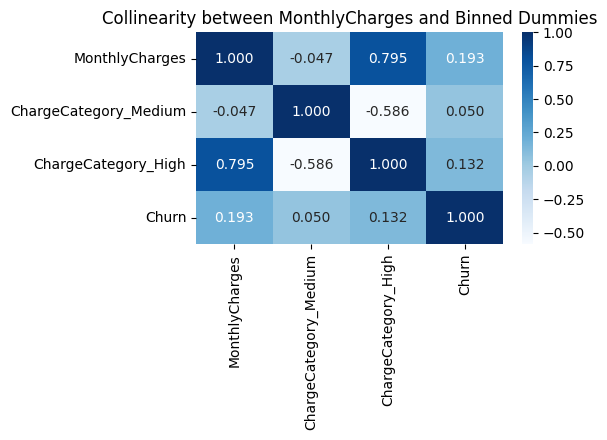

In [2]:
# Replicate original binning
df_audit = df_clean.copy()
df_audit['ChargeCategory'] = pd.cut(df_audit['MonthlyCharges'], bins=[0, 40, 80, 150], labels=['Low', 'Medium', 'High'])
charge_dummies = pd.get_dummies(df_audit['ChargeCategory'], prefix='ChargeCategory', drop_first=True)
df_audit = pd.concat([df_audit, charge_dummies], axis=1)

# Correlation analysis between raw MonthlyCharges and derived dummies
corr_matrix = df_audit[['MonthlyCharges', 'ChargeCategory_Medium', 'ChargeCategory_High', 'Churn']].corr()
print('Correlation Matrix:')
display(corr_matrix.round(4))

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(corr_matrix, annot=True, cmap='Blues', fmt='.3f', ax=ax)
ax.set_title('Collinearity between MonthlyCharges and Binned Dummies')
plt.tight_layout()
plt.show()

### Audit Conclusions on ChargeCategory Dummies:
1. **Information Loss:** Discretizing `MonthlyCharges` into 3 broad bins discards continuous variance and fine-grained price sensitivities.  
2. **Severe Collinearity:** Retaining both continuous `MonthlyCharges` and the dummy flags introduces multicollinearity in linear/logistic models without providing any new signal.  
3. **Arbitrary Thresholds:** The bin limits (40, 80) were selected without empirical justification.  
4. **Methodological Recommendation:** Retain continuous `MonthlyCharges`. If non-linear relationships are present, tree-based models (Random Forest, XGBoost) discover optimal split thresholds directly from continuous values.

## 3. Principled Domain Feature Engineering
We construct business-informed, non-leaking features:
1. **`tenure_group`**: Customer lifecycle cohorts (0-12m, 13-24m, 25-48m, 49-60m, 61-72m).
2. **`total_services`**: Aggregate count of all subscribed active services (phone, internet, add-ons).
3. **`security_services_count`**: Count of security/protection services (`OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`).
4. **`streaming_services_count`**: Count of entertainment services (`StreamingTV`, `StreamingMovies`).
5. **`is_fiber_optic`**: Binary indicator for high-risk fiber optic internet technology.
6. **`is_automatic_payment`**: Binary indicator for low-risk automated payment methods (bank transfer, credit card).
7. **`is_long_term_contract`**: Binary indicator for one-year or two-year commitments.
8. **`avg_monthly_charges`**: Lifetime average monthly spend ($TotalCharges / (tenure + 1)$).
9. **`charge_escalation_ratio`**: Current monthly charge divided by historical average monthly charge (detects price shocks).

In [3]:
from src.features.engineering import engineer_features

df_featured = engineer_features(df_clean)
print(f'Engineered dataset shape: {df_featured.shape[0]} rows, {df_featured.shape[1]} columns.\n')
print('New feature columns created:')
new_cols = [c for c in df_featured.columns if c not in df_clean.columns]
for col in new_cols:
    print(f'  - {col}: dtype {df_featured[col].dtype}, nulls: {df_featured[col].isnull().sum()}')

Engineered dataset shape: 7043 rows, 31 columns.

New feature columns created:
  - tenure_group: dtype category, nulls: 0
  - security_services_count: dtype int64, nulls: 0
  - streaming_services_count: dtype int64, nulls: 0
  - total_services: dtype int64, nulls: 0
  - has_internet: dtype int64, nulls: 0
  - is_fiber_optic: dtype int64, nulls: 0
  - is_automatic_payment: dtype int64, nulls: 0
  - is_long_term_contract: dtype int64, nulls: 0
  - avg_monthly_charges: dtype float64, nulls: 0
  - charge_escalation_ratio: dtype float64, nulls: 0


## 4. Target Leakage Verification
Ensure no input feature was constructed using `Churn`.

In [4]:
# Calculate correlation of new features with target
numeric_cols = df_featured.select_dtypes(include=[np.number]).columns
target_corrs = df_featured[numeric_cols].corr()['Churn'].sort_values()
print('Feature Correlations with Churn:')
display(target_corrs.to_frame('Correlation_with_Churn'))

# Verify no feature has an impossible perfect correlation (r = 1.0 or r = -1.0)
leaking_features = [col for col in numeric_cols if col != 'Churn' and abs(target_corrs[col]) > 0.95]
print(f'Potentially leaking features (|r| > 0.95): {leaking_features}')
assert len(leaking_features) == 0, 'Target leakage detected!'

Feature Correlations with Churn:


,Correlation_with_Churn
is_long_term_contract,-0.405103
tenure,-0.352229
is_automatic_payment,-0.209902
TotalCharges,-0.198324
security_services_count,-0.173061
charge_escalation_ratio,-0.020837
total_services,-0.019375
streaming_services_count,0.071162
avg_monthly_charges,0.072579
SeniorCitizen,0.150889


Potentially leaking features (|r| > 0.95): []


## 5. Production Pipeline & Preprocessing Architecture
In contrast to fitting `LabelEncoder` globally across all columns, an industry-standard pipeline uses `ColumnTransformer` with distinct treatment for:
- **Numeric Features:** Imputation (if needed) + Standard Scaling.
- **Binary Features:** Direct 0/1 representation (no expansion).
- **Nominal Categorical Features:** `OneHotEncoder(drop='first', handle_unknown='ignore')`.

Ensembling this within `sklearn.pipeline.Pipeline` guarantees that encoders and scalers are **fitted strictly on training folds**, completely eliminating data leakage.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Define feature groups for ML ColumnTransformer
numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges', 'avg_monthly_charges', 'charge_escalation_ratio']
binary_features = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling',
                   'has_internet', 'is_fiber_optic', 'is_automatic_payment', 'is_long_term_contract']
nominal_features = ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
                    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
                    'Contract', 'PaymentMethod', 'tenure_group']

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

nominal_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('nom', nominal_transformer, nominal_features)
], remainder='passthrough')

print('Configured ColumnTransformer architecture successfully:')
print(preprocessor)

Configured ColumnTransformer architecture successfully:
ColumnTransformer(remainder='passthrough',
                  transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['tenure', 'MonthlyCharges', 'TotalCharges',
                                  'avg_monthly_charges',
                                  'charge_escalation_ratio']),
                                ('nom',
                                 Pipeline(steps=[('onehot',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['MultipleLines', 'InternetService',
          

## 6. Export Featured Dataset & Automated Validation
Save the finalized feature dataset to `data/processed/telco_customer_churn_featured.csv`.

In [6]:
df_featured.to_csv(FEATURED_DATA_PATH, index=False)
print(f'Finalized feature dataset exported to: {FEATURED_DATA_PATH}')

# Automated assertions
assert len(df_featured) == 7043, 'Row count mismatch!'
assert df_featured['customerID'].nunique() == 7043, 'customerID not unique!'
assert df_featured['Churn'].isnull().sum() == 0, 'Churn nulls present!'
assert not df_featured.select_dtypes(include=[np.number]).isin([np.inf, -np.inf]).any().any(), 'Infinite values present!'
print('ALL 4 FEATURE VALIDATION ASSERTIONS PASSED!')

Finalized feature dataset exported to: D:\Data-analytics\AI-Churn-Prediction-Model\data\processed\telco_customer_churn_featured.csv
ALL 4 FEATURE VALIDATION ASSERTIONS PASSED!
